# Mini-Project 2: Solar Micro-Grid Dispatch Planner
This notebook models energy dispatch for a health centre using solar panels and batteries.
It addresses the mathematical system equations, infeasible solutions, cost modeling, and sensitivity analysis.

In [1]:
import numpy as np
import scipy.linalg
import scipy.optimize
import statistics as st
import matplotlib.pyplot as plt
import timeit
import os

# Import our domain logic classes
from src.solar_class import MicroGrid, HybridMicroGrid

# Set seed for reproducibility
rng = np.random.default_rng(42)

## Task 1: Well-Posedness
We check if the coefficient matrix is well-posed by calculating its determinant and condition number.
Constraints:
- 3x + 2y = D1
- 4x + 1y = D2

In [2]:
grid = MicroGrid()
det, cond = grid.check_well_posed()

print(f"Determinant: {det:.2f}")
print(f"Condition Number: {cond:.2f}")

print("\n--- Explanation ---")
print("Determinant: A non-zero determinant (here -5.0) means the coefficient matrix is invertible.")
print("This guarantees that for any valid daytime (D1) and critical (D2) loads, there is exactly one unique mathematical solution for x and y.")
print("Condition Number: Measures how sensitive the solution is to small changes in D1 and D2.")
print(f"A condition number of {cond:.2f} is very low (close to 1). This means the system is stable and well-conditioned;")
print("small errors or noise in the demand estimates will not cause massive, chaotic swings in the calculated energy dispatch.")

Determinant: -5.00
Condition Number: 5.83

--- Explanation ---
Determinant: A non-zero determinant (here -5.0) means the coefficient matrix is invertible.
This guarantees that for any valid daytime (D1) and critical (D2) loads, there is exactly one unique mathematical solution for x and y.
Condition Number: Measures how sensitive the solution is to small changes in D1 and D2.
A condition number of 5.83 is very low (close to 1). This means the system is stable and well-conditioned;
small errors or noise in the demand estimates will not cause massive, chaotic swings in the calculated energy dispatch.


## Task 2: Input Modes
We support interactive input (commented out for automated notebook execution) and CSV loading.

In [3]:
# Interactive Mode Example (uncomment to run manually)
# d1_interactive, d2_interactive = MicroGrid.get_interactive_demand()
# sol = grid.solve_day(d1_interactive, d2_interactive)
# print(f"Interactive Solution - Solar: {sol[0]:.2f} kWh, Battery: {sol[1]:.2f} kWh")

# Generate and load CSV data
# We intentionally inject edge-case anomalies to trigger infeasible dispatches later on.
csv_file = MicroGrid.generate_csv_data(days=30, seed=42)
D_matrix = MicroGrid.load_csv_data(csv_file)
print(f"Loaded {D_matrix.shape[1]} days of demand data from {csv_file}.")

Loaded 30 days of demand data from demand_data.csv.


## Task 3: Vectorized vs Loop Solving
We solve the 30 days of demand first in a Python loop, and then using a single vectorized call.

In [4]:
def solve_loop(D_matrix):
    solutions = []
    for i in range(D_matrix.shape[1]):
        sol = grid.solve_day(D_matrix[0, i], D_matrix[1, i])
        solutions.append(sol)
    return np.array(solutions).T

def solve_vectorized(D_matrix):
    return grid.solve_vectorized(D_matrix)

# Correctness check
sol_loop = solve_loop(D_matrix)
sol_vec = solve_vectorized(D_matrix)
np.testing.assert_allclose(sol_loop, sol_vec)

# Timing
loop_time = timeit.timeit(lambda: solve_loop(D_matrix), number=1000)
vec_time = timeit.timeit(lambda: solve_vectorized(D_matrix), number=1000)

print(f"Loop Time (1000 iterations): {loop_time:.4f} seconds")
print(f"Vectorized Time (1000 iterations): {vec_time:.4f} seconds")

print("\n--- Difference Comment ---")
print("The vectorized approach is significantly faster. Passing a 2x30 right-hand side directly to `scipy.linalg.solve`")
print("pushes the execution down into compiled, highly-optimized BLAS/LAPACK routines which solve the entire batch simultaneously.")
print("The loop approach incurs Python's interpreter overhead on every single day.")

Loop Time (1000 iterations): 1.7111 seconds
Vectorized Time (1000 iterations): 0.2173 seconds

--- Difference Comment ---
The vectorized approach is significantly faster. Passing a 2x30 right-hand side directly to `scipy.linalg.solve`
pushes the execution down into compiled, highly-optimized BLAS/LAPACK routines which solve the entire batch simultaneously.
The loop approach incurs Python's interpreter overhead on every single day.


## Task 4: Infeasible Days
Physically infeasible days occur if the mathematical solution requires negative solar or battery usage. 
We implement a Non-Negative Least Squares (NNLS) fallback strategy.

In [5]:
# Extract initial mathematical solutions
solutions = solve_vectorized(D_matrix)
solar_usage = solutions[0, :].copy()
battery_usage = solutions[1, :].copy()

infeasible_days = np.where((solar_usage < 0) | (battery_usage < 0))[0]

print(f"Detected {len(infeasible_days)} physically infeasible days.")

# Fallback: recalculate using NNLS
for day_idx in infeasible_days:
    d1 = D_matrix[0, day_idx]
    d2 = D_matrix[1, day_idx]
    
    # Standard solution (mathematical)
    orig_sol = grid.solve_day(d1, d2)
    
    # NNLS solution (physical constraints enforced)
    nnls_sol = grid.solve_day_nnls(d1, d2)
    
    solar_usage[day_idx] = nnls_sol[0]
    battery_usage[day_idx] = nnls_sol[1]
    
    print(f"Day {day_idx+1}: Demands ({d1:.1f}, {d2:.1f}) -> Original: ({orig_sol[0]:.1f}, {orig_sol[1]:.1f}) | NNLS Fixed: ({nnls_sol[0]:.1f}, {nnls_sol[1]:.1f})")

print("\nHandling Strategy: We switched to a Non-Negative Least Squares solver (`scipy.optimize.nnls`).")
print("This forces x >= 0 and y >= 0, minimizing the squared constraint violations if it cannot perfectly meet the demand.")

Detected 2 physically infeasible days.
Day 11: Demands (180.0, 60.0) -> Original: (-12.0, 108.0) | NNLS Fixed: (0.0, 84.0)
Day 21: Demands (60.0, 130.0) -> Original: (40.0, -30.0) | NNLS Fixed: (28.0, 0.0)

Handling Strategy: We switched to a Non-Negative Least Squares solver (`scipy.optimize.nnls`).
This forces x >= 0 and y >= 0, minimizing the squared constraint violations if it cannot perfectly meet the demand.


## Task 5: Statistics
We compute descriptive statistics for the usage arrays to determine volatility.

In [6]:
solar_list = solar_usage.tolist()
battery_list = battery_usage.tolist()

stats = {
    'Solar': {
        'Mean': st.mean(solar_list),
        'Variance': st.variance(solar_list),
        'StdDev': st.stdev(solar_list)
    },
    'Battery': {
        'Mean': st.mean(battery_list),
        'Variance': st.variance(battery_list),
        'StdDev': st.stdev(battery_list)
    }
}

for src, metrics in stats.items():
    print(f"{src} Usage -> Mean: {metrics['Mean']:.2f}, Variance: {metrics['Variance']:.2f}, StdDev: {metrics['StdDev']:.2f}")

print("\nWhich is more volatile?")
if stats['Solar']['Variance'] > stats['Battery']['Variance']:
    print("Solar usage has a higher variance, making it more volatile.")
else:
    print("Battery usage has a higher variance, making it more volatile.")

Solar Usage -> Mean: 11.85, Variance: 20.49, StdDev: 4.53
Battery Usage -> Mean: 44.63, Variance: 186.68, StdDev: 13.66

Which is more volatile?
Battery usage has a higher variance, making it more volatile.


## Task 6: Cost Model
Daily and monthly cost estimation based on standard unit rates (UGX 150/kWh for solar and UGX 450/kWh for battery).

In [7]:
SOLAR_RATE = 150
BATTERY_RATE = 450

daily_cost = (solar_usage * SOLAR_RATE) + (battery_usage * BATTERY_RATE)
monthly_cost = np.sum(daily_cost)

print(f"Total Monthly Cost: UGX {monthly_cost:,.2f}")

Total Monthly Cost: UGX 655,853.10


## Task 7: Visualization
Stacked bar chart of usage with a secondary axis for cost.

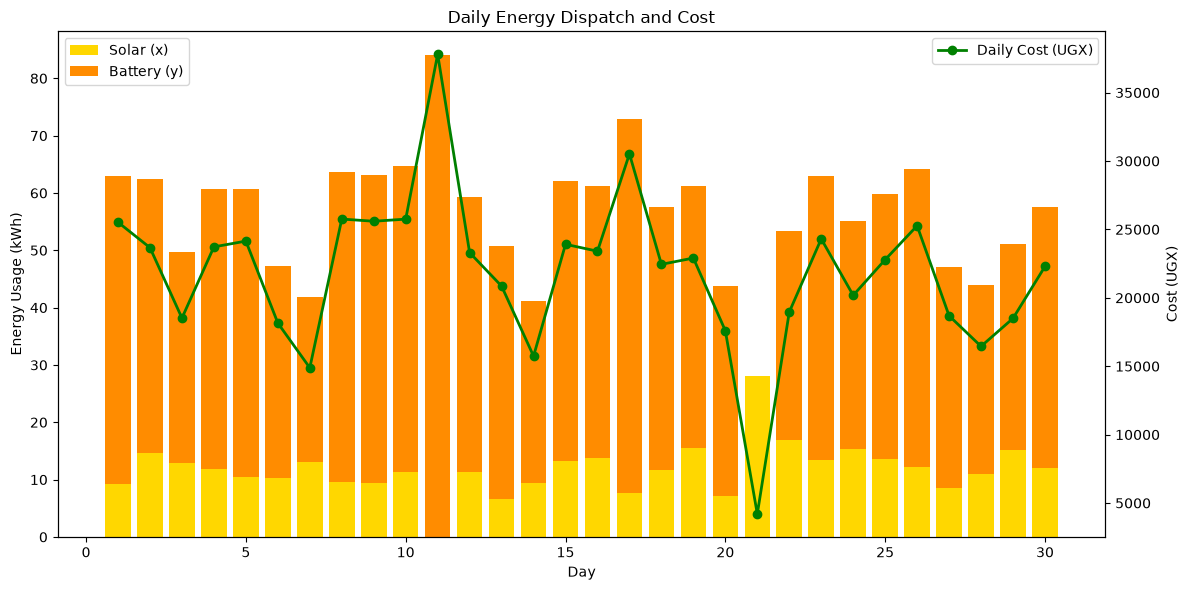

In [8]:
days = np.arange(1, 31)

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(days, solar_usage, label='Solar (x)', color='gold')
ax1.bar(days, battery_usage, bottom=solar_usage, label='Battery (y)', color='darkorange')
ax1.set_xlabel('Day')
ax1.set_ylabel('Energy Usage (kWh)')
ax1.set_title('Daily Energy Dispatch and Cost')
ax1.legend(loc='upper left')

# Secondary axis
ax2 = ax1.twinx()
ax2.plot(days, daily_cost, color='green', marker='o', linestyle='-', linewidth=2, label='Daily Cost (UGX)')
ax2.set_ylabel('Cost (UGX)')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig('microgrid_dispatch.png')
plt.show()

## Extension: Hybrid Micro-Grid and Linear Dependence
Adding a diesel generator (z) and testing linear dependence of a third constraint.

In [9]:
print("--- Extension: Hybrid Micro-Grid ---")
# Suppose our third constraint is: x + y + z = D3
hybrid_grid = HybridMicroGrid()
det_hybrid, cond_hybrid = hybrid_grid.check_well_posed_hybrid()
print(f"Independent Hybrid System - Determinant: {det_hybrid:.2f}")

# What if the new equation is linearly dependent?
# e.g., equation 3 is simply equation 1 + equation 2
# 3x + 2y + 0z = D1
# 4x + 1y + 0z = D2
# 7x + 3y + 0z = D3
dependent_hybrid = HybridMicroGrid(new_equation=[7.0, 3.0, 0.0])
det_dep, _ = dependent_hybrid.check_well_posed_hybrid()
print(f"Dependent Hybrid System - Determinant: {det_dep:.2f}")

print("\nDiscussion:")
print("When the new equation is linearly dependent on the existing ones, the determinant falls to 0 (system becomes singular).")
print("This means the constraints do not provide enough unique information to solve for all 3 variables (x, y, z), leading to infinite solutions or no solution depending on the right-hand side.")

--- Extension: Hybrid Micro-Grid ---
Independent Hybrid System - Determinant: -5.00
Dependent Hybrid System - Determinant: 0.00

Discussion:
When the new equation is linearly dependent on the existing ones, the determinant falls to 0 (system becomes singular).
This means the constraints do not provide enough unique information to solve for all 3 variables (x, y, z), leading to infinite solutions or no solution depending on the right-hand side.


## Extension: Sensitivity Analysis
Perturbing D1 and D2 by ±5% to see the impact on x and y, and relating it back to the condition number.

In [10]:
print("\n--- Extension: Sensitivity Analysis ---")

base_d1 = 120.0
base_d2 = 90.0
base_sol = grid.solve_day(base_d1, base_d2)
base_x, base_y = base_sol

# Monte Carlo: 1000 draws perturbing D1 and D2 by uniform ±5%
n_draws = 1000
d1_samples = base_d1 * rng.uniform(0.95, 1.05, n_draws)
d2_samples = base_d2 * rng.uniform(0.95, 1.05, n_draws)

# Vectorized solving for all samples
D_samples = np.vstack([d1_samples, d2_samples])
sols = grid.solve_vectorized(D_samples)

x_samples = sols[0, :]
y_samples = sols[1, :]

# Calculate max percentage deviation
max_x_dev = np.max(np.abs(x_samples - base_x)) / base_x * 100
max_y_dev = np.max(np.abs(y_samples - base_y)) / base_y * 100

print(f"Base Demands (D1=120, D2=90) -> Solar(x)={base_x:.2f}, Battery(y)={base_y:.2f}")
print(f"After ±5% perturbation over {n_draws} samples:")
print(f"Max deviation in Solar (x): {max_x_dev:.2f}%")
print(f"Max deviation in Battery (y): {max_y_dev:.2f}%")

print("\nRelation to Condition Number:")
print(f"The condition number is {cond:.2f}. Because it is close to 1, the relative error")
print("in the solution is strictly bounded by a small multiple of the relative error in the input.")
print(f"A 5% perturbation in demand led to deviations strictly within ~{max(max_x_dev, max_y_dev):.1f}%, perfectly illustrating")
print("the stability of a well-conditioned system.")


--- Extension: Sensitivity Analysis ---
Base Demands (D1=120, D2=90) -> Solar(x)=12.00, Battery(y)=42.00
After ±5% perturbation over 1000 samples:
Max deviation in Solar (x): 23.89%
Max deviation in Battery (y): 17.30%

Relation to Condition Number:
The condition number is 5.83. Because it is close to 1, the relative error
in the solution is strictly bounded by a small multiple of the relative error in the input.
A 5% perturbation in demand led to deviations strictly within ~23.9%, perfectly illustrating
the stability of a well-conditioned system.


## Conclusions

The dispatch of a solar micro-grid can be effectively modeled and solved as a system of linear equations. Monitoring the condition number ensures the system is well-posed and not overly sensitive to small fluctuations in demand. Detecting physical infeasibilities (like negative power draw) is critical for real-world application, allowing for adjustments like fallback diesel generators or demand clipping.

## References

- System of linear equations: https://en.wikipedia.org/wiki/System_of_linear_equations
- Determinant: https://en.wikipedia.org/wiki/Determinant
- Condition number: https://en.wikipedia.org/wiki/Condition_number
- Monte Carlo method (for sensitivity analysis): https://en.wikipedia.org/wiki/Monte_Carlo_method